# UD1 — El código funciona, ¿la conclusión también?

## Por qué necesitamos estadística en un sistema de datos

Dos demostraciones con **datos, tablas y gráficas**. Antes de ejecutar cada bloque, toma una decisión; después comprueba si la mantienes. No necesitas aprender modelos de IA ni desplegar infraestructura.

1. **Cuarteto de Anscombe:** cuatro datasets con resúmenes estadísticos casi idénticos. ¿Podemos usar el mismo modelo para todos?
2. **CadenaRetail:** una campaña parece peor en el total, pero mejora en cada segmento. ¿Qué estamos midiendo realmente?

**Duración orientativa:** 35–50 minutos. Ejecutar las celdas de arriba abajo.

**Origen de los datos:** Anscombe es un ejemplo construido clásico, no una muestra de clientes reales. CadenaRetail es una simulación didáctica de 2.000 visitas, no evidencia de una empresa. Los problemas que ilustran sí aparecen en dashboards, pipelines y análisis reales.

## Preparación

En Jupyter o VS Code necesitas Python con `numpy`, `pandas` y `matplotlib`. Si faltan, instalar en el entorno que usa el kernel: `python -m pip install numpy pandas matplotlib`. En Colab suelen estar disponibles.

Los datos están incluidos en el notebook: **no se necesita conexión a Internet para ejecutarlo** una vez preparado el entorno.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 11})
pd.set_option('display.max_columns', 12)
COLORES = {'A': '#2563eb', 'B': '#ea580c'}

## 1. Anscombe: un resumen no es el dataset

Imagina que un servicio recibe pares `(x, y)` de cuatro fuentes y publica medias, varianzas, correlación y una recta de ajuste. No hay errores de formato ni valores nulos.

**Pregunta de ingeniería:** si los indicadores coinciden, ¿es razonable que el servicio aplique la misma interpretación a las cuatro fuentes? Primero veremos únicamente los números.

Los valores clásicos están documentados en el [paquete datasets de R](https://stat.ethz.ch/R-manual/R-devel/library/datasets/html/anscombe.html). Referencia: F. J. Anscombe (1973), *Graphs in Statistical Analysis*, DOI [10.1080/00031305.1973.10478966](https://doi.org/10.1080/00031305.1973.10478966).

In [2]:
x_comun = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
datos_anscombe = {
    'I': (x_comun, [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]),
    'II': (x_comun, [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]),
    'III': (x_comun, [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]),
    'IV': ([8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8], [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]),
}
anscombe = pd.concat(
    [pd.DataFrame({'fuente': nombre, 'x': x, 'y': y})
     for nombre, (x, y) in datos_anscombe.items()], ignore_index=True
)
assert len(anscombe) == 44 and not anscombe.isna().any().any()

# Tabla de los datos originales: cada par de columnas corresponde a una fuente.
display(pd.DataFrame({
    f'{nombre}_{variable}': valores
    for nombre, (x, y) in datos_anscombe.items()
    for variable, valores in [('x', x), ('y', y)]
}))

,I_x,I_y,II_x,II_y,III_x,III_y,IV_x,IV_y
0,10,8.04,10,9.14,10,7.46,8,6.58
1,8,6.95,8,8.14,8,6.77,8,5.76
2,13,7.58,13,8.74,13,12.74,8,7.71
3,9,8.81,9,8.77,9,7.11,8,8.84
4,11,8.33,11,9.26,11,7.81,8,8.47
5,14,9.96,14,8.10,14,8.84,8,7.04
6,6,7.24,6,6.13,6,6.08,8,5.25
7,4,4.26,4,3.10,4,5.39,19,12.50
8,12,10.84,12,9.13,12,8.15,8,5.56
9,7,4.82,7,7.26,7,6.42,8,7.91


In [3]:
filas_resumen = []
for nombre, grupo in anscombe.groupby('fuente', sort=False):
    pendiente, intercepto = np.polyfit(grupo['x'], grupo['y'], deg=1)
    r = grupo['x'].corr(grupo['y'])
    filas_resumen.append({
        'fuente': nombre, 'n': len(grupo),
        'media_x': grupo['x'].mean(), 'media_y': grupo['y'].mean(),
        'var_x': grupo['x'].var(ddof=1), 'var_y': grupo['y'].var(ddof=1),
        'r_Pearson': r, 'pendiente': pendiente, 'intercepto': intercepto,
    })
resumen_anscombe = pd.DataFrame(filas_resumen).set_index('fuente')
display(resumen_anscombe.round(2))
print('Varianzas muestrales: divisor n−1. Recta: y ≈ intercepto + pendiente × x.')
print('Los valores son casi iguales; no afirmamos igualdad exacta con los datos redondeados.')

,n,media_x,media_y,var_x,var_y,r_Pearson,pendiente,intercepto
fuente,,,,,,,,
I,11,9.0,7.5,11.0,4.13,0.82,0.5,3.0
II,11,9.0,7.5,11.0,4.13,0.82,0.5,3.0
III,11,9.0,7.5,11.0,4.12,0.82,0.5,3.0
IV,11,9.0,7.5,11.0,4.12,0.82,0.5,3.0


Varianzas muestrales: divisor n−1. Recta: y ≈ intercepto + pendiente × x.
Los valores son casi iguales; no afirmamos igualdad exacta con los datos redondeados.


### Detente antes de ver las gráficas

Escribe una hipótesis: **¿las cuatro fuentes representan la misma relación?** ¿Aplicarías la recta `y ≈ 3 + 0,5x` a las cuatro?

La tabla muestra aproximadamente `media(x)=9`, `media(y)=7,5`, `var(x)=11`, `var(y)=4,12` y `r=0,82`. El cálculo es correcto. Ahora veremos lo que no cuenta.

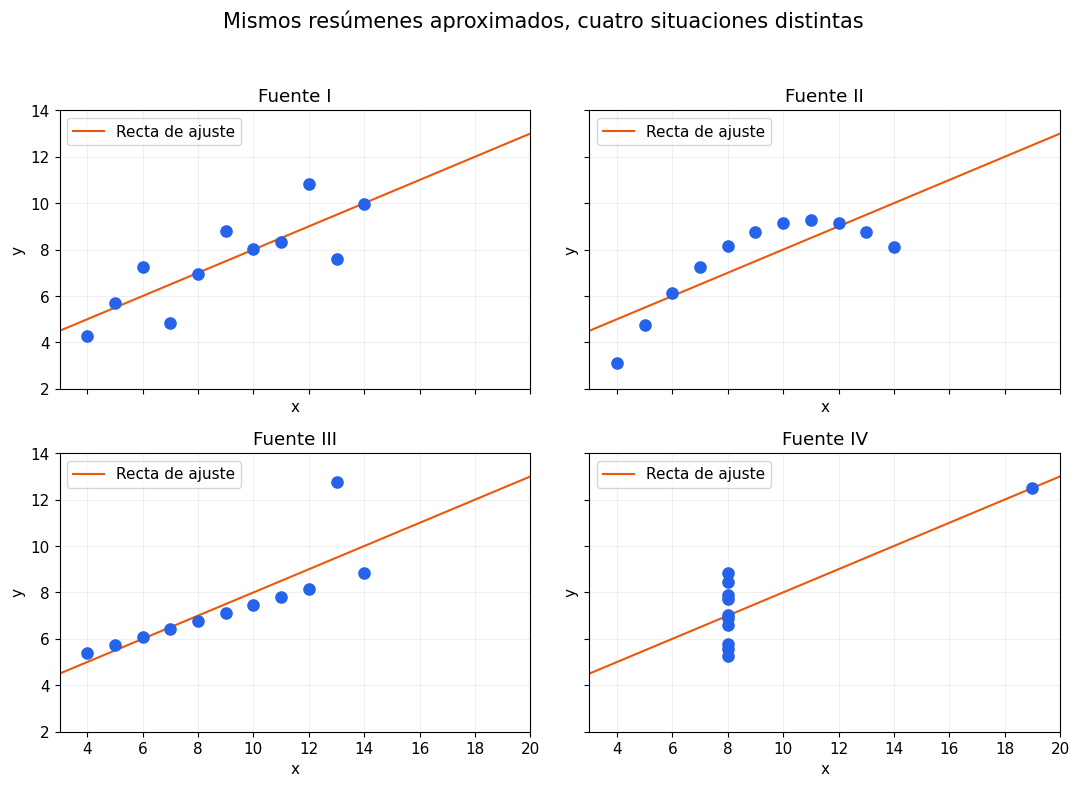

In [4]:
fig, ejes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)
x_recta = np.linspace(3, 20, 100)
for eje, (nombre, grupo) in zip(ejes.flat, anscombe.groupby('fuente', sort=False)):
    pendiente = resumen_anscombe.loc[nombre, 'pendiente']
    intercepto = resumen_anscombe.loc[nombre, 'intercepto']
    eje.scatter(grupo['x'], grupo['y'], s=65, color='#2563eb', zorder=3)
    eje.plot(x_recta, intercepto + pendiente * x_recta, color='#ea580c', label='Recta de ajuste')
    eje.set(title=f'Fuente {nombre}', xlabel='x', ylabel='y', xlim=(3, 20), ylim=(2, 14))
    eje.grid(alpha=0.2)
    eje.legend(loc='upper left')
fig.suptitle('Mismos resúmenes aproximados, cuatro situaciones distintas', fontsize=15)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

### ¿Qué decisión cambia al ver el scatter plot?

| Fuente | Lo que muestra la gráfica | Decisión técnica razonable |
|---|---|---|
| I | Relación aproximadamente lineal, con dispersión. | La recta puede describir una tendencia; comprobar residuos y límites antes de usarla. |
| II | Curva: al crecer x, y primero sube y luego baja. | No interpretar la correlación como prueba de linealidad; estudiar una relación no lineal. |
| III | Casi todos los puntos están en una recta, excepto uno. | Investigar el punto y medir cuánto cambia el ajuste; no borrarlo por reflejo. |
| IV | Diez observaciones tienen x=8 y solo una tiene x=19. | El rango de x tiene muy poca cobertura; una única observación sostiene el ajuste. No generalizar una recta sin más datos. |

**No se trata de elegir entre estadística y gráficas.** Hay que combinar resúmenes, distribución, gráficos y contexto. Una correlación puede calcularse correctamente y ser insuficiente para decidir.

In [5]:
# Experimento de sensibilidad; NO es una receta de limpieza.
sensibilidad = []
for nombre in ['III', 'IV']:
    grupo = anscombe[anscombe['fuente'].eq(nombre)].copy()
    indice = grupo['y'].idxmax() if nombre == 'III' else grupo['x'].idxmax()
    sin_punto = grupo.drop(index=indice)
    pendiente_sin = (float(np.polyfit(sin_punto['x'], sin_punto['y'], 1)[0])
                     if sin_punto['x'].nunique() > 1 else np.nan)
    sensibilidad.append({
        'fuente': nombre, 'punto_retirado': tuple(grupo.loc[indice, ['x', 'y']]),
        'pendiente_original': resumen_anscombe.loc[nombre, 'pendiente'],
        'pendiente_sin_punto': pendiente_sin,
        'x_distintos_restantes': sin_punto['x'].nunique(),
    })
display(pd.DataFrame(sensibilidad).round(3))
print('En IV, NaN significa que no se puede identificar una pendiente: todas las x restantes son iguales.')
print('Retirar el punto sirve aquí para medir sensibilidad; aceptar o rechazarlo requiere investigar su origen.')

,fuente,punto_retirado,pendiente_original,pendiente_sin_punto,x_distintos_restantes
0,III,"(13, 12.74)",0.5,0.345,10
1,IV,"(19, 12.5)",0.5,NaN,1


En IV, NaN significa que no se puede identificar una pendiente: todas las x restantes son iguales.
Retirar el punto sirve aquí para medir sensibilidad; aceptar o rechazarlo requiere investigar su origen.


## 2. CadenaRetail: el dashboard calcula bien, pero puede engañar

Dirección compara dos periodos con campañas A y B. El indicador es la **tasa de conversión**: visitas que terminan en compra / visitas totales.

La población contiene dos segmentos, definidos por un criterio previo a la compra: **alta intención** y **baja intención**. No son categorías inferidas a partir de la propia compra.

Los datos siguientes son sintéticos, diseñados para mostrar una inversión entre la comparación agregada y la comparación por grupos (**paradoja de Simpson**). Cada fila representa una visita, no una persona única ni el importe de una venta.

**Pregunta:** si B convierte menos en el total, ¿deberíamos apagarla?

In [6]:
# Campaña, segmento, visitas, compras. Se generan filas individuales sin datos personales.
plan_simulacion = [
    ('A', 'Alta intención', 900, 720),
    ('A', 'Baja intención', 100, 20),
    ('B', 'Alta intención', 100, 85),
    ('B', 'Baja intención', 900, 225),
]
registros = []
for campaña, segmento, visitas, compras in plan_simulacion:
    assert 0 <= compras <= visitas
    registros.extend({'campaña': campaña, 'segmento': segmento, 'compra': int(i < compras)}
                     for i in range(visitas))
visitas = pd.DataFrame(registros).sample(frac=1, random_state=42).reset_index(drop=True)
visitas.insert(0, 'visita_id', np.arange(1, len(visitas) + 1))

# Controles de calidad: todos pasan, pero NO garantizan una interpretación correcta.
assert len(visitas) == 2000
assert visitas['visita_id'].is_unique
assert not visitas.isna().any().any()
assert visitas['compra'].isin([0, 1]).all()
display(visitas.head(12))
print('2.000 filas válidas, identificadores únicos, sin nulos y con compra en {0, 1}.')

,visita_id,campaña,segmento,compra
0,1,B,Baja intención,0
1,2,A,Alta intención,1
2,3,B,Baja intención,0
3,4,A,Baja intención,1
4,5,B,Baja intención,1
5,6,B,Baja intención,1
6,7,A,Baja intención,0
7,8,B,Baja intención,0
8,9,A,Alta intención,1
9,10,B,Baja intención,1


2.000 filas válidas, identificadores únicos, sin nulos y con compra en {0, 1}.


,visitas,compras,conversión_pct
campaña,,,
A,1000,740,74.0
B,1000,310,31.0


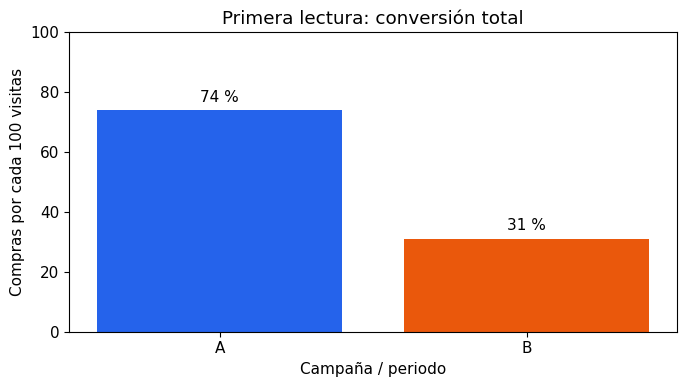

In [7]:
global_campaña = visitas.groupby('campaña').agg(
    visitas=('visita_id', 'size'), compras=('compra', 'sum'), conversión=('compra', 'mean')
)
display(global_campaña.assign(conversión_pct=100 * global_campaña['conversión']).drop(columns='conversión'))

fig, eje = plt.subplots(figsize=(7, 4))
valores = global_campaña['conversión'] * 100
barras = eje.bar(valores.index, valores, color=[COLORES[c] for c in valores.index])
eje.bar_label(barras, labels=[f'{v:.0f} %' for v in valores], padding=4)
eje.set(title='Primera lectura: conversión total', xlabel='Campaña / periodo', ylabel='Compras por cada 100 visitas', ylim=(0, 100))
fig.tight_layout()
plt.show()

### Detente: A tiene 74 % y B tiene 31 %

El cambio es de **−43 puntos porcentuales**, no de −43 %. ¿Recomendarías mantener A y retirar B?

Antes de responder: **¿las visitas son comparables?** ¿Ha cambiado la mezcla de segmentos? Un `GROUP BY campaña` correcto no responde esas preguntas.

visitas  compras  conversión_pct  peso_pct
campaña segmento                                                  
A       Alta intención      900      720            80.0      90.0
        Baja intención      100       20            20.0      10.0
B       Alta intención      100       85            85.0      10.0
        Baja intención      900      225            25.0      90.0

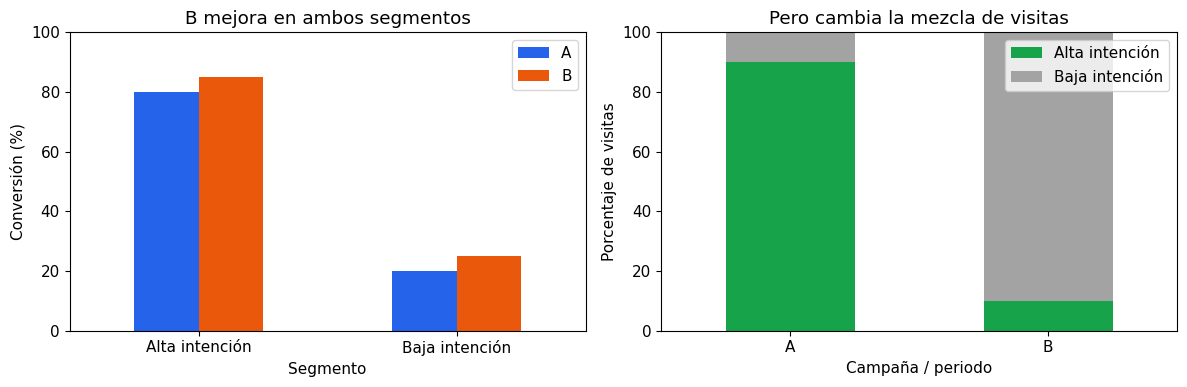

In [8]:
por_segmento = visitas.groupby(['campaña', 'segmento']).agg(
    visitas=('visita_id', 'size'), compras=('compra', 'sum'), conversión=('compra', 'mean')
)
por_segmento['peso_en_campaña'] = (
    por_segmento['visitas'] / por_segmento.groupby(level='campaña')['visitas'].transform('sum')
)
display(por_segmento.assign(
    conversión_pct=100 * por_segmento['conversión'],
    peso_pct=100 * por_segmento['peso_en_campaña']
).drop(columns=['conversión', 'peso_en_campaña']).round(1))

tasas = por_segmento['conversión'].unstack('segmento')
mezcla = por_segmento['peso_en_campaña'].unstack('segmento')
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
(tasas.T * 100).plot.bar(ax=ejes[0], color=COLORES, rot=0)
ejes[0].set(title='B mejora en ambos segmentos', ylabel='Conversión (%)', xlabel='Segmento', ylim=(0, 100))
(mezcla * 100).plot.bar(stacked=True, ax=ejes[1], color=['#16a34a', '#a3a3a3'], rot=0)
ejes[1].set(title='Pero cambia la mezcla de visitas', ylabel='Porcentaje de visitas', xlabel='Campaña / periodo', ylim=(0, 100))
for eje in ejes:
    eje.legend(loc='upper right')
fig.tight_layout()
plt.show()

### La inversión se explica por los pesos

- En **alta intención**, B pasa del 80 % al 85 %.
- En **baja intención**, B pasa del 20 % al 25 %.
- Pero A recibe un 90 % de visitas de alta intención; B, solo un 10 %.

La tasa global es una **media ponderada** de tasas:

`A = 0,90 × 0,80 + 0,10 × 0,20 = 0,74`

`B = 0,10 × 0,85 + 0,90 × 0,25 = 0,31`

La mejora dentro de cada segmento queda escondida por el cambio de composición. No hay un fallo del programa: hemos usado un resumen que responde una pregunta distinta.

**¿Es inútil el 31 %?** No: describe correctamente las visitas reales de B. Es insuficiente para atribuir la diferencia a la campaña.

,Conversión observada (%),Conversión con mezcla común (%)
campaña,,
A,74.0,50.0
B,31.0,55.0


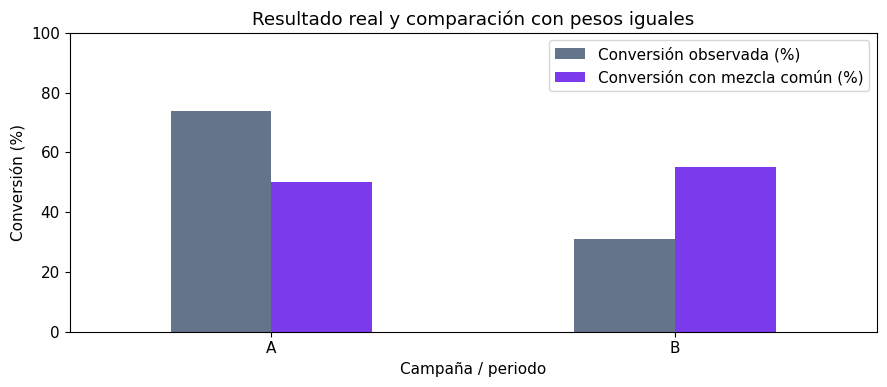

In [9]:
# Comparación hipotética con una mezcla común: 50 % de cada segmento.
# No reemplaza los resultados reales ni demuestra causalidad.
pesos_comunes = pd.Series({'Alta intención': 0.5, 'Baja intención': 0.5})
conversion_comparable = tasas.mul(pesos_comunes, axis='columns').sum(axis=1)
comparacion = pd.DataFrame({
    'Conversión observada (%)': global_campaña['conversión'] * 100,
    'Conversión con mezcla común (%)': conversion_comparable * 100,
})
display(comparacion.round(1))
fig, eje = plt.subplots(figsize=(9, 4))
comparacion.plot.bar(ax=eje, rot=0, color=['#64748b', '#7c3aed'])
eje.set(title='Resultado real y comparación con pesos iguales', ylabel='Conversión (%)', xlabel='Campaña / periodo', ylim=(0, 100))
fig.tight_layout()
plt.show()

# Comprobaciones del ejemplo: las dos lecturas deben diferir, tal como se ha diseñado.
assert np.allclose(global_campaña['conversión'].loc[['A', 'B']], [0.74, 0.31])
assert (tasas.loc['B'] > tasas.loc['A']).all()
assert np.allclose(conversion_comparable.loc[['A', 'B']], [0.50, 0.55])

## 3. ¿Qué cambia en nuestro sistema?

| Antes | Después de explorar |
|---|---|
| Publicar solo una tasa de conversión global. | Publicar numerador, denominador, tasas por segmento y composición de las visitas. |
| Guardar únicamente el KPI agregado. | Conservar el nivel de detalle y el segmento definido antes del resultado para poder auditar. |
| Alertar «B es peor» al bajar la media. | Alertar sobre el cambio de mezcla y revisar si la comparación sigue siendo válida. |
| Aplicar una recta porque la correlación es alta. | Revisar scatter plot, cobertura de x, residuos y sensibilidad a observaciones concretas. |
| Asumir que validación de tipos significa dato útil. | Separar validez técnica de representatividad y capacidad de responder la pregunta. |

**No hemos demostrado que B cause una mejora.** Los periodos y visitantes son diferentes. Para valorar el efecto de la campaña, habría que diseñar una comparación adecuada, por ejemplo un experimento aleatorizado que tenga en cuenta los segmentos, y estudiar la incertidumbre. La estandarización muestra el efecto de los pesos, no fabrica evidencia causal.

Este trabajo es estadística aplicada al sistema: definir qué se mide, explorar cómo se distribuye, comprobar comparabilidad y documentar los límites. Es justamente lo que necesitaremos al hacer EDA.

## 4. Actividad de cierre: defiende una decisión

En parejas, elegid uno de los casos y escribid cuatro líneas:

1. **Decisión inicial:** ¿qué habríais hecho mirando solo la tabla resumen?
2. **Evidencia nueva:** ¿qué gráfica o tabla os obliga a matizarla?
3. **Cambio técnico:** ¿qué conservaríais o añadiríais al pipeline/dashboard?
4. **Límite:** ¿qué no podéis concluir todavía?

### Un experimento corto con código

En el bloque de pesos comunes cambia `0.5/0.5` por `0.8/0.2` (ambos deben sumar 1). Antes de recalcular, predice qué campaña tendrá mayor tasa comparable. **No cambies los datos observados**: cambia solo la pregunta hipotética. Las comprobaciones finales esperan los pesos originales, por lo que habrá que actualizar o comentar esa última aserción al explorar otros pesos.

### Ticket de salida individual

> Un cálculo correcto que podría llevarme a una conclusión equivocada es…
> La evidencia que necesito antes de tomar la decisión es…

**Idea final:** automatizar un número no significa comprenderlo. Necesitamos estadística, gráficas y contexto para saber qué decisión puede sostener ese número.